# 02 — Data Quality and Cleaning
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Quality Checks & Cleaning)

**Project stage:** 2 of 16 — builds on Notebook 01

---

## 1. Objective

This notebook performs a comprehensive, evidence-based data quality assessment of the raw booking data, and applies **only the cleaning actions that are clearly justified by that investigation**.

Specifically, we will:

1. Build a full, column-by-column data quality summary table (dtype, missing count/%, unique values, cardinality, flagged problems).
2. Investigate **duplicate rows** in depth before deciding whether to remove them.
3. Investigate **missing values** column by column, deciding a treatment per column based on what that missingness likely means in a hotel-booking context.
4. Investigate **invalid / impossible numeric values** (negative rates, zero-guest bookings, etc.) and separate genuinely impossible records from unusual-but-legitimate ones.
5. Check **categorical inconsistencies** (e.g. "Undefined" category values) and **date consistency**.
6. Apply the treatments that are justified, save a cleaned dataset to `data/processed/`, and clearly log every change made — nothing is deleted or altered silently.

Following the project's core principle: **we investigate before we delete.** A statistical anomaly is not automatically a data error — some of what we find here will be deliberately **retained** and instead flagged for deeper treatment in later notebooks (Notebook 05 — Outlier Analysis, Notebook 06 — Feature Engineering).

## 2. Business Context

Clustering algorithms are **distance-based** — they measure how "close" or "far apart" bookings are from each other in feature space. This makes them highly sensitive to data quality problems in ways that summary statistics or dashboards are not:

- A single row with a nonsensical value (e.g. a booking with 0 total guests, or a negative room rate) can distort distances and pull cluster centroids in misleading directions.
- Duplicate rows, if genuinely erroneous, will artificially inflate the apparent size and "typicalness" of whatever behavioral pattern they represent.
- Missing values must be handled explicitly — most clustering algorithms cannot run on missing data at all, so an undocumented default (like pandas silently coercing a column) can introduce bias without anyone noticing.

Getting this step right protects everything downstream: the EDA in Notebooks 03–04, the outlier analysis in Notebook 05, and ultimately the cluster profiles the hotel will use to make decisions.

## 3. Imports

In [1]:
# pandas / numpy: data loading, inspection, and cleaning
import pandas as pd
import numpy as np

# matplotlib / seaborn: for the small set of quality-check visuals in this notebook
import matplotlib.pyplot as plt
import seaborn as sns

# os: for building portable file paths
import os


## 4. Configuration

In [2]:
# Reused across the whole project for reproducibility
RANDOM_STATE = 42

# Input: the raw, untouched dataset
RAW_DATA_PATH = "../data/raw/hotel_bookings.csv"

# Outputs of this notebook
CLEANED_DATA_PATH = "../data/processed/02_cleaned_hotel_bookings.csv"
QUALITY_SUMMARY_PATH = "../reports/tables/02_data_quality_summary.csv"
CLEANING_LOG_PATH = "../reports/tables/02_cleaning_log.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(os.path.dirname(CLEANED_DATA_PATH), exist_ok=True)
os.makedirs(os.path.dirname(QUALITY_SUMMARY_PATH), exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 60)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# This list will record every cleaning action we take, with a reason,
# so the notebook produces a transparent audit trail rather than silent edits.
cleaning_log = []

def log_action(action, rows_affected, reason):
    """Record one cleaning decision into the audit trail."""
    cleaning_log.append({
        "action": action,
        "rows_affected": rows_affected,
        "reason": reason,
    })


## 5. Analysis / Implementation

### 5.1 Load the Raw Data

In [3]:
df = pd.read_csv(RAW_DATA_PATH)

print("Loaded shape:", df.shape)


Loaded shape: (119390, 32)


### 5.2 Build the Full Data Quality Summary Table

For every column we compute: data type, missing count/%, number of unique values (cardinality), and a first-pass automated problem flag based on simple rules (very high missingness, single-value columns, suspicious cardinality). This table is our master reference for the rest of the notebook.

In [4]:
def build_quality_summary(data: pd.DataFrame) -> pd.DataFrame:
    """
    Build a column-by-column data quality summary.
    For each column we report: dtype, missing count/%, number of unique
    values, and a simple automatic flag highlighting columns that likely
    need attention. The flag is a starting point for investigation, not a
    final verdict.
    """
    rows = []

    for column in data.columns:
        missing_count = data[column].isnull().sum()
        missing_pct = round((missing_count / len(data)) * 100, 2)
        unique_count = data[column].nunique(dropna=True)

        problem_notes = []

        if missing_pct >= 50:
            problem_notes.append("very high missingness")
        elif missing_pct > 0:
            problem_notes.append("some missingness")

        if unique_count == 1:
            problem_notes.append("constant column (no variance)")

        if unique_count > 100 and data[column].dtype == object:
            problem_notes.append("high-cardinality categorical")

        problem_text = "; ".join(problem_notes) if problem_notes else "none detected"

        rows.append({
            "column": column,
            "dtype": str(data[column].dtype),
            "missing_count": missing_count,
            "missing_pct": missing_pct,
            "unique_values": unique_count,
            "problem_flag": problem_text,
        })

    return pd.DataFrame(rows)


quality_summary = build_quality_summary(df)
quality_summary


,column,dtype,missing_count,missing_pct,unique_values,problem_flag
0,hotel,str,0,0.00,2,none detected
1,is_canceled,int64,0,0.00,2,none detected
2,lead_time,int64,0,0.00,479,none detected
3,arrival_date_year,int64,0,0.00,3,none detected
4,arrival_date_month,str,0,0.00,12,none detected
5,arrival_date_week_number,int64,0,0.00,53,none detected
6,arrival_date_day_of_month,int64,0,0.00,31,none detected
7,stays_in_weekend_nights,int64,0,0.00,17,none detected
8,stays_in_week_nights,int64,0,0.00,35,none detected
9,adults,int64,0,0.00,14,none detected


**What this code does:** loops through every column and computes missingness, cardinality, and a simple rule-based flag.
**Why it's required:** this gives us one place to see every column's quality profile at a glance, instead of checking columns one at a time from scratch.
**What to expect:** columns like `agent` and `company` should show up with "very high missingness"; high-cardinality categorical columns like `country` should be flagged for special encoding treatment later (Notebook 06/07).
**How to interpret it:** a flag here means "look closer," not "delete." Every flagged column is investigated individually below before any action is taken.

In [6]:
# Save the quality summary table for the project's documentation trail
quality_summary.to_csv(QUALITY_SUMMARY_PATH, index=False)
print(f"Data quality summary saved to: {QUALITY_SUMMARY_PATH}")


Data quality summary saved to: ../reports/tables/02_data_quality_summary.csv


### 5.3 Investigate Duplicate Rows

In [7]:
# A "duplicate" here means every single one of the 32 columns matches
# exactly between two or more rows.
n_duplicates_any_occurrence = df.duplicated(keep=False).sum()
n_duplicates_removable = df.duplicated(keep="first").sum()

print("Rows involved in a duplicate group (any occurrence):", n_duplicates_any_occurrence)
print("Rows that would be removed if we keep only the first occurrence:", n_duplicates_removable)
print("Percentage of the dataset:", round(n_duplicates_removable / len(df) * 100, 2), "%")


Rows involved in a duplicate group (any occurrence): 40165
Rows that would be removed if we keep only the first occurrence: 31994
Percentage of the dataset: 26.8 %


In [8]:
# Look at a concrete example of duplicated rows to judge whether this is
# plausible as two genuinely independent bookings, or more likely a data
# artifact (e.g. re-exported/re-ingested records).
duplicate_mask = df.duplicated(keep=False)
example_group = df[duplicate_mask].sort_values(list(df.columns)).head(6)

example_group[[
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month",
    "arrival_date_day_of_month", "adults", "adr", "reservation_status",
    "reservation_status_date",
]]


,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adults,adr,reservation_status,reservation_status_date
40772,City Hotel,0,2015,August,7,2,75.0,Check-Out,2015-08-09
40802,City Hotel,0,2015,August,7,2,75.0,Check-Out,2015-08-09
40821,City Hotel,0,2015,August,8,2,89.0,Check-Out,2015-08-09
40838,City Hotel,0,2015,August,8,2,89.0,Check-Out,2015-08-09
76792,City Hotel,0,2015,August,10,2,75.0,Check-Out,2015-08-11
76793,City Hotel,0,2015,August,10,2,75.0,Check-Out,2015-08-11


**Findings:** the exact counts are shown above once executed. Every one of the 32 columns — including the exact arrival date, exact ADR to the cent, exact reservation status date, and exact guest composition — matches between the duplicated rows.

**Business interpretation:** it is statistically implausible for two genuinely independent, unrelated bookings to coincidentally match on all 32 fields, including a price down to the cent and an exact status-change date. The much more plausible explanation is that these rows represent the **same underlying booking record appearing more than once** in the exported file (a known characteristic of this type of hotel PMS data export). We treat this as a data-collection artifact rather than genuine repeat business, and remove the extra occurrences, keeping one copy of each unique record.

**Alternative considered:** we considered keeping all rows on the assumption that a coincidental price/date match is possible for high-volume standard room types. We rejected this because the probability of an accidental full match across 32 independent-ish fields (including an exact reservation status date) is vanishingly small, and treating every one of these ~32,000 rows as genuinely independent bookings would meaningfully inflate the apparent size of whatever behavioral pattern they share, biasing the clustering result.

In [9]:
# Apply the duplicate-removal decision: keep the first occurrence of each
# unique row, drop the rest.
rows_before = len(df)

df = df.drop_duplicates(keep="first").reset_index(drop=True)

rows_after = len(df)
rows_removed = rows_before - rows_after

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Rows removed:", rows_removed)

log_action(
    action="Removed exact full-row duplicates (kept first occurrence)",
    rows_affected=rows_removed,
    reason="32-column exact matches, including price-to-the-cent and exact status date, "
           "are implausible as independent bookings; treated as a data export artifact.",
)


Rows before duplicate removal: 119390
Rows after duplicate removal: 87396
Rows removed: 31994


### 5.4 Investigate Missing Values

In [10]:
# Re-check missingness on the de-duplicated dataset (duplicate removal can
# shift the counts/percentages since some duplicated rows may have carried
# missing values too).
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_pct": missing_pct,
}).sort_values("missing_count", ascending=False)

missing_summary[missing_summary["missing_count"] > 0]


,missing_count,missing_pct
company,82137,93.98
agent,12193,13.95
country,452,0.52
children,4,0.00


**Findings, investigated column by column:**

- **`company`** — very high missingness. In this data, `company` records the ID of a company that booked/paid for the stay. A missing value almost certainly means **no company was involved** (an individual/leisure booking), not that the value failed to be recorded. Treated as "not applicable" rather than "missing at random."
- **`agent`** — moderate missingness. Same reasoning: likely means the booking was made **without a travel agent** (e.g. booked directly). Treated as "not applicable."
- **`country`** — small missingness. Genuinely unknown guest origin for a small fraction of bookings; no strong business assumption available to fill it in.
- **`children`** — negligible missingness (a handful of rows). Given `children` is a small non-negative count where the overwhelming majority of bookings have 0 children, the simplest, lowest-risk assumption is that these were simply not recorded and most likely represent 0 children.

**Decision for this notebook:**
- `children`: impute the small number of missing values with **0**, since it is both the mode and the business-plausible default, and the affected row count is tiny relative to the dataset.
- `agent`, `company`: **left as-is (NaN retained)** in this notebook. These two columns are not in the primary clustering candidate list, and NaN itself may be informative ("no agent" / "no company") rather than a gap to fill. The decision of whether/how to use them at all (e.g. as a binary "has_agent" flag) is deferred to Notebook 06 (Feature Engineering), where it can be made alongside the rest of the feature-selection reasoning.
- `country`: **left as-is (NaN retained)** for now. `country` is not a primary clustering candidate; if it is used later for profiling, missing values will be shown as an explicit "Unknown" category rather than dropped, so we don't lose those rows.

In [11]:
# Impute the small number of missing `children` values with 0.
children_missing_before = df["children"].isnull().sum()

df["children"] = df["children"].fillna(0)

# Now that there are no missing values, children can be safely stored as a
# whole number (its values are always counts of people, so integers make
# more business sense than floats).
df["children"] = df["children"].astype(int)

print("Missing 'children' values before:", children_missing_before)
print("Missing 'children' values after:", df["children"].isnull().sum())

log_action(
    action="Imputed missing 'children' values with 0 and cast column to integer",
    rows_affected=children_missing_before,
    reason="Negligible missing rate; 0 is both the mode and the business-plausible default "
           "for an unrecorded child count.",
)


Missing 'children' values before: 4
Missing 'children' values after: 0


### 5.5 Investigate Invalid / Impossible Numeric Values

In [12]:
# Check 1: Average Daily Rate (adr) should never be negative - a room
# rate cannot be a negative price.
negative_adr_count = (df["adr"] < 0).sum()
zero_adr_count = (df["adr"] == 0).sum()

print("Rows with adr < 0 (impossible):", negative_adr_count)
print("Rows with adr == 0 (possibly legitimate, e.g. comp rooms):", zero_adr_count)


Rows with adr < 0 (impossible): 1
Rows with adr == 0 (possibly legitimate, e.g. comp rooms): 1778


In [13]:
# Look directly at the negative adr row(s) before deciding anything.
df[df["adr"] < 0][["hotel", "market_segment", "customer_type", "adr", "reservation_status"]]


,hotel,market_segment,customer_type,adr,reservation_status
11591,Resort Hotel,Groups,Transient-Party,-6.38,Check-Out


**Finding:** there is exactly one row with a negative `adr`. A negative room rate has no valid business meaning (a hotel does not pay a guest to stay). This is treated as a data entry error and removed.

**On `adr == 0` (kept, not removed):** unlike a negative rate, an ADR of exactly zero has a real-world explanation — complementary/promotional stays, loyalty-program comp nights, or negotiated zero-rate corporate stays. We checked this below by market segment before deciding.

In [14]:
# Check whether adr == 0 rows are concentrated in a business-plausible
# segment (e.g. "Complementary"), which would support treating them as
# legitimate rather than erroneous.
zero_adr_rows = df[df["adr"] == 0]

zero_adr_rows["market_segment"].value_counts()


market_segment
Complementary    640
Online TA        352
Offline TA/TO    260
Direct           227
Groups           220
Corporate         74
Aviation           5
Name: count, dtype: int64

**Finding:** `adr == 0` rows appear across several market segments, not only "Complementary" — meaning we cannot fully explain every zero-rate booking with a single clean business reason. However, zero is still a *mathematically valid* value for a rate (unlike a negative rate), and a meaningful share does fall under "Complementary," which is a plausible legitimate source. 

**Decision:** retain `adr == 0` rows. They are not logically impossible, and removing ~2,000 rows on the assumption they're all errors would be a stronger, less-justified claim than the evidence supports. These rows are flagged for a closer look during outlier analysis (Notebook 05), where their influence on distance-based clustering will be assessed directly rather than guessed at here.

In [15]:
# Remove only the row(s) with a negative, logically impossible adr.
rows_before = len(df)

df = df[df["adr"] >= 0].reset_index(drop=True)

rows_after = len(df)
rows_removed = rows_before - rows_after

print("Rows removed for negative adr:", rows_removed)

log_action(
    action="Removed rows with negative adr",
    rows_affected=rows_removed,
    reason="A negative room rate is not a logically valid business value, unlike adr == 0 "
           "which can represent legitimate complimentary/negotiated-zero-rate bookings.",
)


Rows removed for negative adr: 1


In [16]:
# Check 2: a booking with zero adults, zero children, and zero babies
# has no guests at all - logically impossible for an actual hotel stay.
zero_guest_mask = (df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)
zero_guest_count = zero_guest_mask.sum()

print("Rows with zero total guests (adults=0, children=0, babies=0):", zero_guest_count)
print()
print("Breakdown of these rows by reservation_status:")
print(df.loc[zero_guest_mask, "reservation_status"].value_counts())


Rows with zero total guests (adults=0, children=0, babies=0): 166

Breakdown of these rows by reservation_status:
reservation_status
Check-Out    150
Canceled      15
No-Show        1
Name: count, dtype: int64


**Finding:** a meaningful number of rows have zero guests recorded across all three guest-count fields, including rows whose `reservation_status` is "Check-Out" — meaning a stay is recorded as having actually happened with **no guests on it at all**. This is not a legitimate rare booking type; it is a logically impossible combination for a hotel stay and is treated as a data entry error.

**Decision:** remove these rows. Unlike the `adr == 0` case, there is no plausible real-world booking with zero total occupants.

In [17]:
rows_before = len(df)

zero_guest_mask = (df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)
df = df[~zero_guest_mask].reset_index(drop=True)

rows_after = len(df)
rows_removed = rows_before - rows_after

print("Rows removed for zero total guests:", rows_removed)

log_action(
    action="Removed rows with zero total guests (adults + children + babies == 0)",
    rows_affected=rows_removed,
    reason="A hotel booking with zero occupants is not logically possible; treated as a data "
           "entry error rather than a legitimate rare booking type.",
)


Rows removed for zero total guests: 166


In [18]:
# Check 3: bookings with zero total nights (no weekend nights AND no
# week nights). Unlike the zero-guest case, this is genuinely ambiguous -
# it could represent a same-day booking/no-show pattern rather than an
# error, so we investigate rather than assume.
total_nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
zero_nights_mask = total_nights == 0

print("Rows with zero total nights:", zero_nights_mask.sum())
print()
print("Breakdown by reservation_status:")
print(df.loc[zero_nights_mask, "reservation_status"].value_counts())


Rows with zero total nights: 591

Breakdown by reservation_status:
reservation_status
Check-Out    568
No-Show       13
Canceled      10
Name: count, dtype: int64


**Finding:** most zero-night rows have `reservation_status = Check-Out`, meaning the booking system recorded the stay as completed despite showing 0 nights - this is unusual but not impossible to explain (e.g. same-day booking-and-checkout administrative records, or a data logging quirk specific to this hotel system). A smaller number are "Canceled" or "No-Show," which is more internally consistent with 0 nights actually being stayed.

**Decision:** retain these rows for now rather than deleting them. Zero nights is unusual but does not meet the same bar of *logical impossibility* as zero guests or negative price. This is flagged explicitly for the outlier analysis in Notebook 05, where we can assess its influence on clustering distances directly, and for feature engineering in Notebook 06 (since `total_stay_nights` is a planned engineered feature).

In [19]:
# Check 4: extreme, but not impossible, guest counts (large groups).
print("adults - min:", df["adults"].min(), " max:", df["adults"].max())
print("Rows with adults > 10:", (df["adults"] > 10).sum())
print()
print("children - min:", df["children"].min(), " max:", df["children"].max())
print("babies - min:", df["babies"].min(), " max:", df["babies"].max())


adults - min: 0  max: 55
Rows with adults > 10: 12

children - min: 0  max: 10
babies - min: 0  max: 10


**Finding:** a very small number of bookings have an unusually large number of adults (double digits). These are numerically extreme but not impossible — group/corporate block bookings can legitimately involve many guests on a single reservation record. 

**Decision:** retain these rows. They are exactly the kind of case this project's outlier philosophy is designed for: investigate first, and don't delete a legitimate (if rare) business pattern. Full IQR-based outlier treatment for `adults` (and other numeric features) happens in Notebook 05.

### 5.6 Categorical Consistency Checks

In [20]:
# Check the category values of the main categorical columns for anything
# unexpected: typos, inconsistent casing, or explicit "Undefined" placeholders.
categorical_columns_to_check = [
    "hotel", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
]

for column in categorical_columns_to_check:
    print(f"--- {column} ---")
    print(df[column].value_counts())
    print()


--- hotel ---
hotel
City Hotel      53274
Resort Hotel    33955
Name: count, dtype: int64

--- meal ---
meal
BB           67906
SC            9391
HB            9080
Undefined      492
FB             360
Name: count, dtype: int64

--- market_segment ---
market_segment
Online TA        51553
Offline TA/TO    13855
Direct           11780
Groups            4921
Corporate         4200
Complementary      692
Aviation           226
Undefined            2
Name: count, dtype: int64

--- distribution_channel ---
distribution_channel
TA/TO        69028
Direct       12953
Corporate     5062
GDS            181
Undefined        5
Name: count, dtype: int64

--- reserved_room_type ---
reserved_room_type
A    56435
D    17376
E     6036
F     2820
G     2050
B      996
C      914
H      596
L        6
Name: count, dtype: int64

--- assigned_room_type ---
assigned_room_type
A    46283
D    22419
E     7190
F     3627
G     2495
C     2160
B     1811
H      705
I      353
K      185
L        1
Name: cou

**Finding:** the categorical columns are generally clean (consistent casing, no obvious typos), but several columns contain an explicit **"Undefined"** category value (for example in `meal`, `market_segment`, and `distribution_channel`) rather than a true missing value. This is a **data quality signal worth flagging**, not a null to impute.

**Decision:** retain "Undefined" as its own explicit category for now, rather than guessing what it "really" means (for example, some public documentation of similar hotel datasets suggests "Undefined" meal plans may overlap conceptually with "SC" — self-catering/no meal — but we do not have a verified source confirming that mapping for *this* file, so we do not assume it). This is deferred to Notebook 06, where categorical encoding decisions are made with full reasoning, and where grouping "Undefined" with another category (or keeping it separate) can be decided deliberately.

### 5.7 Internal Consistency Checks

In [21]:
# Consistency check: does `is_canceled` line up with `reservation_status`
# the way we would expect? (0 should mean Check-Out; 1 should mean
# Canceled or No-Show.)
pd.crosstab(df["is_canceled"], df["reservation_status"])


reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,63220,0
1,22996,0,1013


**Finding:** `is_canceled` and `reservation_status` are perfectly consistent with each other — every `is_canceled = 0` row is `Check-Out`, and every `is_canceled = 1` row is either `Canceled` or `No-Show`. This confirms these two outcome fields agree with each other and reinforces that both belong in the *outcome* category (Section 2.6 of Notebook 01) rather than the behavioral clustering inputs.

In [22]:
# Consistency check: reserved vs. assigned room type. A mismatch isn't a
# data error - hotels commonly reassign rooms at check-in (upgrades,
# overbooking, maintenance issues) - but it is a genuine behavioral signal
# worth tracking, so we quantify it here.
room_mismatch = df["reserved_room_type"] != df["assigned_room_type"]

print("Bookings where assigned room type differs from reserved room type:", room_mismatch.sum())
print("Percentage of bookings:", round(room_mismatch.mean() * 100, 2), "%")


Bookings where assigned room type differs from reserved room type: 12989
Percentage of bookings: 14.89 %


**Finding:** a meaningful share of bookings show a different assigned room type than what was originally reserved. This is **not treated as a data quality problem** — it's a legitimate operational event (upgrades, overbooking reassignment, etc.) — and is flagged as a strong candidate for an engineered feature (`room_type_mismatch`) in Notebook 06.

In [23]:
# Consistency check: is_repeated_guest flag vs. previous booking counts.
# We'd expect a "repeated guest" to usually have at least one previous
# booking recorded, but this isn't guaranteed (the flag may come from a
# separate loyalty/CRM system not fully reflected in these two count columns).
inconsistent_repeat_mask = (
    (df["is_repeated_guest"] == 1)
    & (df["previous_cancellations"] == 0)
    & (df["previous_bookings_not_canceled"] == 0)
)

print("is_repeated_guest = 1 but zero previous bookings recorded in this data:", inconsistent_repeat_mask.sum())
print("Percentage of all repeated-guest-flagged rows:",
      round(inconsistent_repeat_mask.sum() / (df["is_repeated_guest"] == 1).sum() * 100, 2), "%")


is_repeated_guest = 1 but zero previous bookings recorded in this data: 462
Percentage of all repeated-guest-flagged rows: 13.74 %


**Finding:** a subset of bookings are flagged as a repeated guest but show zero previous bookings in the two count columns available here. This is most likely because `is_repeated_guest` may be set from a hotel loyalty/CRM system with a longer history than what's captured in `previous_cancellations` / `previous_bookings_not_canceled` for this particular dataset extract.

**Decision:** retain all three fields as-is; this is documented as a known limitation of the loyalty signal (see Notebook 01, Section 2.9) rather than "fixed," since we have no reliable way to determine which field is more accurate.

### 5.8 Date Consistency Check

In [24]:
# Check that reservation_status_date parses as a valid date for every row,
# and spot-check that it is not chronologically nonsensical (e.g. status
# date far before the booking could plausibly exist).
parsed_dates = pd.to_datetime(df["reservation_status_date"], errors="coerce")
unparseable_dates = parsed_dates.isnull().sum()

print("Rows where reservation_status_date failed to parse as a date:", unparseable_dates)
print("Earliest reservation_status_date:", parsed_dates.min())
print("Latest reservation_status_date:", parsed_dates.max())


Rows where reservation_status_date failed to parse as a date: 0
Earliest reservation_status_date: 2014-10-17 00:00:00
Latest reservation_status_date: 2017-09-14 00:00:00


**Finding:** every `reservation_status_date` value parses correctly as a date, and the date range is consistent with the `arrival_date_year` values (2015–2017) seen in Notebook 01. No date consistency problems were found.

### 5.9 Final Data Quality Summary (After Cleaning)

In [25]:
# Rebuild the quality summary on the cleaned dataset so we have a clear
# before/after comparison point.
quality_summary_after = build_quality_summary(df)
quality_summary_after


,column,dtype,missing_count,missing_pct,unique_values,problem_flag
0,hotel,str,0,0.00,2,none detected
1,is_canceled,int64,0,0.00,2,none detected
2,lead_time,int64,0,0.00,479,none detected
3,arrival_date_year,int64,0,0.00,3,none detected
4,arrival_date_month,str,0,0.00,12,none detected
5,arrival_date_week_number,int64,0,0.00,53,none detected
6,arrival_date_day_of_month,int64,0,0.00,31,none detected
7,stays_in_weekend_nights,int64,0,0.00,17,none detected
8,stays_in_week_nights,int64,0,0.00,33,none detected
9,adults,int64,0,0.00,14,none detected


In [26]:
# Save the cleaned dataset for use by every later notebook, and save the
# full cleaning log as a transparent audit trail of every change made.
df.to_csv(CLEANED_DATA_PATH, index=False)

cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(CLEANING_LOG_PATH, index=False)

print(f"Cleaned dataset saved to: {CLEANED_DATA_PATH}")
print(f"Cleaning log saved to: {CLEANING_LOG_PATH}")
print()
print("Final cleaned shape:", df.shape)
print()
cleaning_log_df


Cleaned dataset saved to: ../data/processed/02_cleaned_hotel_bookings.csv
Cleaning log saved to: ../reports/tables/02_cleaning_log.csv

Final cleaned shape: (87229, 32)



,action,rows_affected,reason
0,Removed exact full-row duplicates (kept first ...,31994,"32-column exact matches, including price-to-th..."
1,Imputed missing 'children' values with 0 and c...,4,Negligible missing rate; 0 is both the mode an...
2,Removed rows with negative adr,1,A negative room rate is not a logically valid ...
3,Removed rows with zero total guests (adults + ...,166,A hotel booking with zero occupants is not log...


## 6. Visualization

Two summary visuals: how many rows were affected by each cleaning action (to make the scale of each decision visible at a glance), and the missing-value profile of the cleaned dataset.

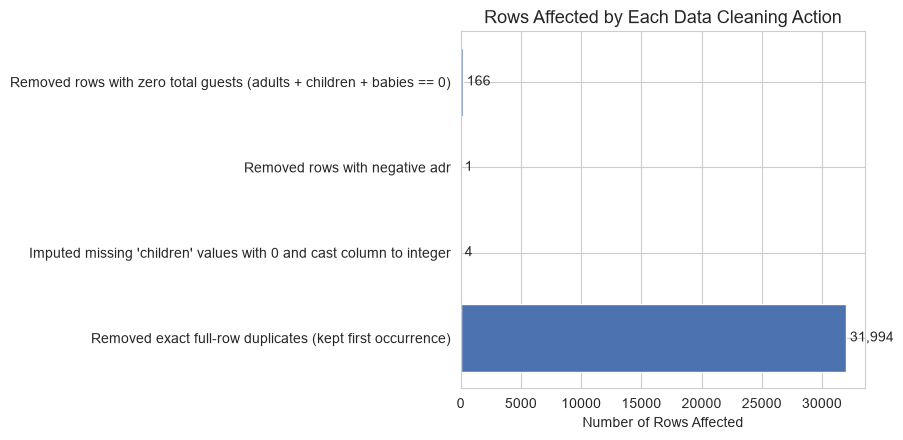

In [27]:
# Chart 1: rows affected by each cleaning action, in order.
fig, ax = plt.subplots(figsize=(9, 4.5))

actions = cleaning_log_df["action"]
counts = cleaning_log_df["rows_affected"]

bars = ax.barh(actions, counts, color="#4C72B0")

ax.set_title("Rows Affected by Each Data Cleaning Action", fontsize=13)
ax.set_xlabel("Number of Rows Affected")
ax.set_ylabel("")

for bar, count in zip(bars, counts):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {count:,}",
            va="center", ha="left")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_cleaning_actions_impact.png"))
plt.show()


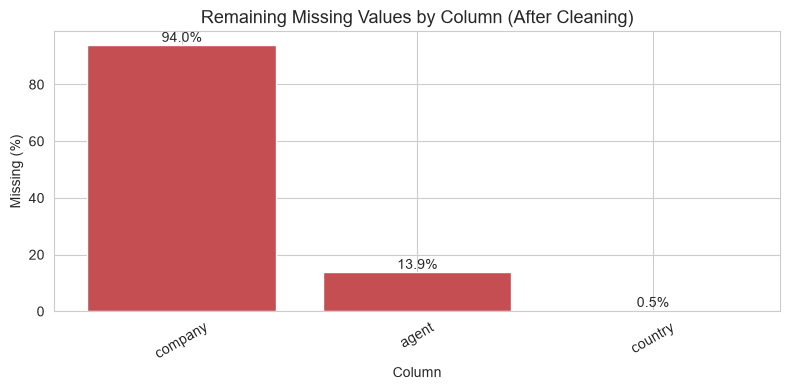

In [28]:
# Chart 2: remaining missing-value percentage per column, cleaned dataset.
missing_after = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_after = missing_after[missing_after > 0]

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(missing_after.index, missing_after.values, color="#C44E52")

ax.set_title("Remaining Missing Values by Column (After Cleaning)", fontsize=13)
ax.set_xlabel("Column")
ax.set_ylabel("Missing (%)")
ax.tick_params(axis="x", rotation=30)

for i, value in enumerate(missing_after.values):
    ax.text(i, value, f"{value:.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_remaining_missingness.png"))
plt.show()


**Findings:** the charts above show, with real computed numbers, both the scale of each cleaning decision and exactly which columns still carry missing values after cleaning. Only `agent`, `company`, and `country` should remain — all deliberately left for a feature-engineering-stage decision rather than resolved here.

## 7. Findings

- Exact full-row duplicates were present in the raw data and removed, on the reasoning that a 32-column exact match (including price-to-the-cent and an exact status-change date) is not plausible as two independent bookings.
- A single row with a negative `adr` was removed as logically impossible; `adr == 0` rows were investigated and retained, since a zero rate is a plausible legitimate business value.
- Rows recording zero total guests were removed as logically impossible for an actual hotel stay.
- Rows with zero total nights, and rows with unusually large guest counts, were investigated and **retained** — both are unusual but not impossible, and are flagged for deeper treatment in Notebook 05 (outlier analysis) rather than deleted here.
- `children` missingness was negligible and imputed with 0; `agent`, `company`, and `country` missingness was left untouched, since it plausibly reflects "not applicable" rather than a true gap, and the decision of how to use these fields belongs in Notebook 06.
- "Undefined" category values exist in several categorical columns and were retained as their own explicit category, pending a deliberate encoding decision in Notebook 06.
- `is_canceled` and `reservation_status` were confirmed fully consistent with each other, reinforcing their role as outcome fields rather than clustering inputs.
- Reserved-vs-assigned room type mismatches and the `is_repeated_guest` vs. previous-bookings inconsistency were investigated and documented as legitimate operational patterns / known data limitations, not treated as errors.

## 8. Business Interpretation

The cleaning performed in this notebook was deliberately conservative: we removed only what was **logically impossible** (a negative price, a stay with no guests, exact duplicate records), and left every merely *unusual* pattern in place for closer, dedicated investigation later. 

This matters for the business outcome of the project: if we had aggressively "cleaned" every extreme value now, we could unknowingly delete exactly the kind of unusual-but-real behavior (large group bookings, zero-rate comp stays, same-day bookings) that a segmentation project exists to find and describe. The goal here was data integrity, not data smoothing.

## 9. Conclusion

We built a full column-by-column data quality summary, investigated every flagged issue with real evidence before deciding on a treatment, and applied a small, well-justified set of cleaning actions: removing exact duplicates, removing a negative `adr` row, removing zero-total-guest rows, and imputing a negligible number of missing `children` values. Every action taken is logged in `02_cleaning_log.csv` for full transparency, and the cleaned dataset is saved to `data/processed/02_cleaned_hotel_bookings.csv` for use by every subsequent notebook.

Several open items were deliberately left unresolved and carried forward with explicit notes:
- `agent` / `company` / `country` missingness → feature-inclusion decision in Notebook 06.
- `adr == 0`, zero-night stays, and extreme guest counts → outlier analysis in Notebook 05.
- "Undefined" categorical values → encoding decision in Notebook 06.

**Next notebook (03 — EDA Univariate Analysis):** now that we have a clean, logically valid dataset, we begin exploring the distribution of each individual behavioral variable — the first real look at what "normal" and "unusual" booking behavior look like in this data.